In [94]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [95]:
df = pd.read_csv('train.csv', usecols=['Age', 'Fare', 'Survived'])

In [96]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [97]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [98]:
df.dropna(inplace=True)

In [99]:
df.shape

(714, 3)

In [100]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [101]:
x = df.iloc[:,1:]
y = df.iloc[:,0]

In [102]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [103]:
x_train.head()

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542
253,30.0,16.1000
719,33.0,7.7750
666,25.0,13.0000


In [104]:
clf = DecisionTreeClassifier()

In [105]:
clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)

In [106]:
accuracy_score(y_test, y_pred)

0.6223776223776224

In [107]:
np.mean(cross_val_score(DecisionTreeClassifier(), x,y, cv=10, scoring='accuracy'))

np.float64(0.6303012519561816)

In [108]:
kbin_age = KBinsDiscretizer(n_bins=15, encode='ordinal', strategy='kmeans')
kbin_fare = KBinsDiscretizer(n_bins=15, encode='ordinal',strategy='kmeans')

In [109]:
trf = ColumnTransformer([
   ('first', kbin_age,[0]),
   ('second', kbin_fare,[1]),
])

In [110]:
x_train_trf = trf.fit_transform(x_train)
x_test_trf = trf.transform(x_test)

In [111]:
print(trf.named_transformers_['first'].n_bins)
print(trf.named_transformers_['second'].n_bins)

15
15


In [112]:
print(trf.named_transformers_['first'].bin_edges_)
print(trf.named_transformers_['second'].bin_edges_)

[array([ 0.42      ,  5.27754049, 11.74158654, 17.35243056, 21.55720029,
        26.64837093, 32.14464286, 37.41916667, 42.9025    , 48.1075    ,
        53.110625  , 58.090625  , 62.3875    , 67.72916667, 75.54166667,
        80.        ])                                                   ]
[array([  0.        ,  11.24103919,  19.86871564,  28.06543126,
         34.90886516,  45.73788324,  59.33660546,  72.27252098,
         84.10950431, 101.00790682, 123.56362348, 144.756475  ,
        185.67419167, 237.86718333, 385.651575  , 512.3292    ])]


In [113]:
output = pd.DataFrame({
    'age': x_train['Age'],
    'age_trf': x_train_trf[:,0],
    'fare': x_train['Fare'],
    'fare_trf': x_train_trf[:,1]

})
output

,age,age_trf,fare,fare_trf
328,31.0,5.0,20.5250,2.0
73,26.0,4.0,14.4542,1.0
253,30.0,5.0,16.1000,1.0
719,33.0,6.0,7.7750,0.0
666,25.0,4.0,13.0000,1.0
...,...,...,...,...
92,46.0,8.0,61.1750,6.0
134,25.0,4.0,13.0000,1.0
337,41.0,7.0,134.5000,10.0
548,33.0,6.0,20.5250,2.0


In [114]:
clf = DecisionTreeClassifier()
clf.fit(x_train_trf,y_train)
y_pred2 = clf.predict(x_test_trf)


In [115]:
accuracy_score(y_test, y_pred2)

0.6433566433566433

In [122]:
def descritize(bins,strategy):

    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)

    trf = ColumnTransformer([
        ('first', kbin_age,[0]),
        ('second', kbin_fare,[1])

    ])

    x_trf = trf.fit_transform(x)
    print(np.mean(cross_val_score(DecisionTreeClassifier(),x,y, cv=10, scoring='accuracy')))

    plt.figure(figsize=(14,4))

    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x['Age'])
    plt.title("Before")

    plt.subplot(122)
    sns.histplot(x_trf[:,0],color='red')
    plt.title("After")

    plt.show()
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x['Fare'])
    plt.title("Before")

    plt.subplot(122)
    sns.histplot(x_trf[:,1],color='red')
    plt.title("Fare")

    plt.show()
    







0.6275234741784036


<Figure size 1400x400 with 0 Axes>

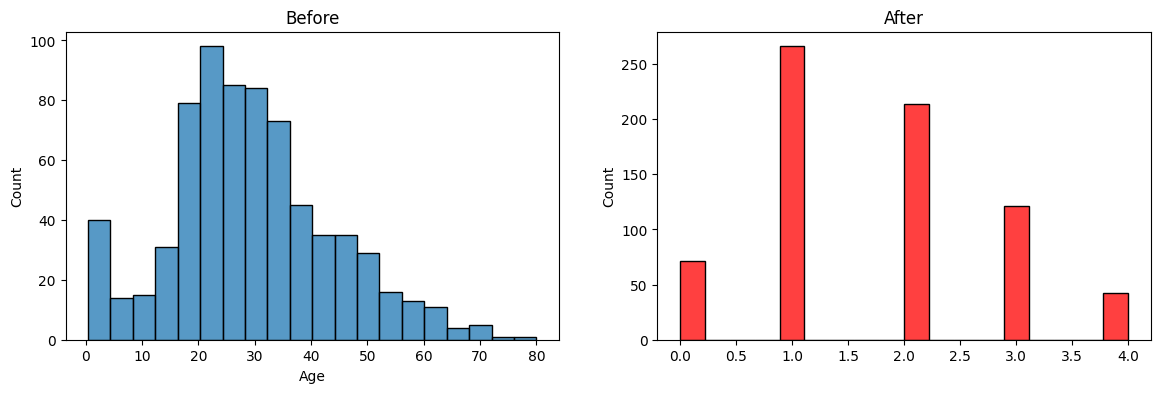

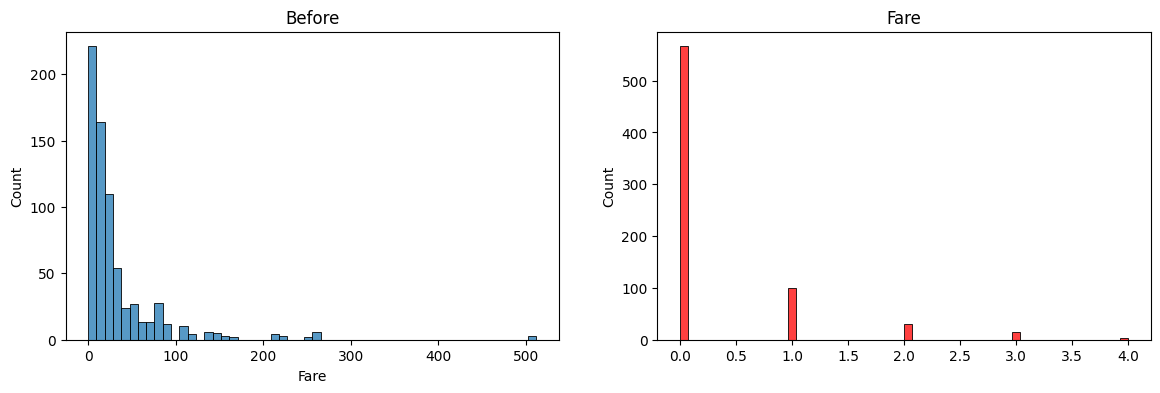

In [123]:
descritize(5,'kmeans')